# Bước 6C — Phân tích theo kiểu che và kiểm chứng resume thực
**Đồ án CV nâng cao · 05/11/2026**

Notebook đọc kết quả pilot đã train thật, kiểm lại số đếm từ predictions, phân tích riêng mắt/dưới/trái/phải và làm phép thử resume: **hai bước liên tục phải bằng một bước → lưu/nạp → bước kế tiếp**, bao gồm optimizer và RNG. Các bước chẩn đoán chạy trên clone, không đổi checkpoint đã chọn hoặc ngân sách B1/B2.

In [1]:
from pathlib import Path
from datetime import datetime,timezone
import os,json,hashlib,io,copy,time,gc
for name in ['OPENBLAS_NUM_THREADS','OMP_NUM_THREADS','MKL_NUM_THREADS']:os.environ[name]='4'
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG',':4096:8')
import numpy as np
import pandas as pd
import torch
from torch import nn
import torch.nn.functional as F
from facenet_pytorch import InceptionResnetV1
from PIL import Image,ImageOps
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
def find_root():
    candidates=[Path(os.environ['CV_PROJECT_ROOT'])] if os.environ.get('CV_PROJECT_ROOT') else []
    candidates.extend([Path.cwd(),*Path.cwd().parents])
    for candidate in candidates:
        if (candidate/'ban_giao_nhom/huan_luyen/Phan_tich_va_kiem_chung_pilot.ipynb').is_file():
            return candidate.resolve()
    raise FileNotFoundError('Mở notebook trong DoAn_CV_NangCao hoặc đặt CV_PROJECT_ROOT.')
ROOT=find_root()
HERE=ROOT/'ban_giao_nhom/huan_luyen';PILOT=HERE/'notebook_outputs'
OUT=HERE/'analysis_outputs';TAB=OUT/'tables';FIG=OUT/'figures'
for p in [OUT,TAB,FIG]:p.mkdir(parents=True,exist_ok=True)
START=time.perf_counter();DEVICE='cuda:0';torch.set_num_threads(4)
torch.backends.cudnn.benchmark=False;torch.backends.cudnn.deterministic=True
torch.backends.cuda.matmul.allow_tf32=False;torch.backends.cudnn.allow_tf32=True
def sha(p):
    h=hashlib.sha256()
    with Path(p).open('rb') as f:
        for b in iter(lambda:f.read(2**20),b''):h.update(b)
    return h.hexdigest()
def state_sha(s):
    h=hashlib.sha256()
    for n,t in sorted(s.items()):h.update(n.encode());h.update(t.detach().cpu().contiguous().numpy().tobytes())
    return h.hexdigest()
def read_rgb160(row):
    path=ROOT/row.path
    raw=path.read_bytes()
    if hashlib.sha256(raw).hexdigest()!=row.sha256:
        raise ValueError(f'SHA-256 ảnh khác manifest: {path}')
    with Image.open(io.BytesIO(raw)) as source:
        image=ImageOps.exif_transpose(source)
        if 'A' in image.getbands():
            rgba=image.convert('RGBA')
            if (np.asarray(rgba.getchannel('A'))<255).any():
                background=Image.new('RGBA',rgba.size,(255,255,255,255))
                image=Image.alpha_composite(background,rgba)
        return np.asarray(image.convert('RGB').resize((160,160),Image.Resampling.BILINEAR),dtype=np.uint8).copy()
def save(d,name):d.to_csv(TAB/(name+'.csv'),index=False,encoding='utf-8-sig',float_format='%.17g');return d
def finish(fig,name):
    for ext in ['png','svg']:fig.savefig(FIG/(name+'.'+ext),bbox_inches='tight',dpi=160)
    display(fig);plt.close(fig)
plt.rcParams.update({'font.family':'Arial','figure.dpi':110,'axes.unicode_minus':False})
summary=json.loads((PILOT/'execution_summary.json').read_text(encoding='utf-8'));assert summary['checks']=='PASS'
pred=pd.read_csv(PILOT/'tables/09_predictions.csv',float_precision='round_trip')
spec=pd.read_csv(ROOT/'ban_giao_nhom/augmentation/notebook_outputs/tables/02_validation_query_variant_specs.csv',dtype={'seed':str})
comparison=pd.read_csv(PILOT/'tables/09_pilot_model_comparison.csv',float_precision='round_trip')
ci=pd.read_csv(PILOT/'tables/09_paired_identity_bootstrap_CI.csv')
assert len(pred)==3*2*7700 and not pred.image_id.isna().any()
inputs={'pilot_summary':sha(PILOT/'execution_summary.json'),'predictions':sha(PILOT/'tables/09_predictions.csv'),
        'variants':sha(ROOT/'ban_giao_nhom/augmentation/notebook_outputs/tables/02_validation_query_variant_specs.csv')}
display(comparison[['run','epoch','DIR','FPIR','occluded_DIR','occluded_FPIR']])

H:\Nam tu\Hoc Ki 1\CV nang cao\Đồ Án\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,run,epoch,DIR,FPIR,occluded_DIR,occluded_FPIR
0,B0,-1,0.571622,0.05,0.227297,0.02750
1,B1,2,0.664865,0.05,0.302973,0.03075
2,B2,2,0.663514,0.05,0.312703,0.03000


## 1. Đếm lại từ predictions và theo từng kiểu che

Score/threshold được so theo float32, export CSV đã giữ đủ chữ số. Mỗi nhóm phải có cả số known và unknown; không chia sai mẫu số do gộp điều kiện. Nhóm che được xác định bằng spec đã chốt trước train, không phải nhóm chọn sau khi xem model.

,run,kind,known_queries,unknown_queries,DIR,FPIR,median_frame_area
0,B0,eyes,939,1013,0.012780,0.003949,0.258809
1,B0,left,939,977,0.408946,0.037871,0.259766
2,B0,lower,937,1003,0.082177,0.033898,0.329766
3,B0,right,885,1007,0.415819,0.034757,0.260000
4,B1,eyes,939,1013,0.036209,0.007897,0.258809
5,B1,left,939,977,0.536741,0.036847,0.259766
6,B1,lower,937,1003,0.113127,0.037886,0.329766
7,B1,right,885,1007,0.538983,0.040715,0.260000
8,B2,eyes,939,1013,0.042599,0.007897,0.258809
9,B2,left,939,977,0.542066,0.036847,0.259766


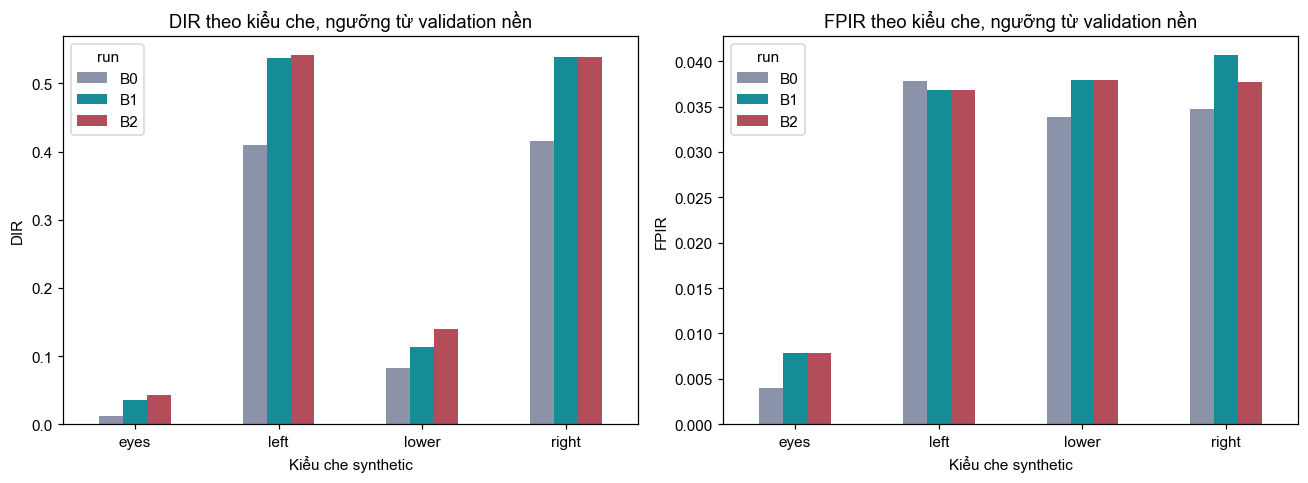

In [2]:
recomputed=[]
for (run,condition),g in pred.groupby(['run','condition']):
    accepted=g.top_score.to_numpy(np.float32)>=g.threshold.to_numpy(np.float32)
    known=g.is_known.to_numpy();correct=g.top1_correct.to_numpy()
    r={'run':run,'condition':condition,'known':int(known.sum()),'unknown':int((~known).sum()),
       'DIR':float((accepted&correct).sum()/known.sum()),'FPIR':float((accepted&~known).sum()/(~known).sum())}
    expected=comparison.set_index('run').loc[run];prefix='' if condition=='base' else 'occluded_'
    assert abs(r['DIR']-expected[prefix+'DIR'])<1e-12 and abs(r['FPIR']-expected[prefix+'FPIR'])<1e-12
    recomputed.append(r)
save(pd.DataFrame(recomputed),'01_metrics_recomputed')
occluded=pred[pred.condition.eq('synthetic_occluded')].merge(spec[['image_id','kind','mask_fraction_frame']],on='image_id',validate='many_to_one')
rows=[]
for (run,kind),g in occluded.groupby(['run','kind']):
    known=g.is_known;accepted=g.accepted
    rows.append({'run':run,'kind':kind,'known_queries':int(known.sum()),'unknown_queries':int((~known).sum()),
                 'DIR':float(g.loc[known,'correct_accepted'].mean()),'FPIR':float(g.loc[~known,'accepted'].mean()),
                 'median_frame_area':g.mask_fraction_frame.median()})
per_kind=save(pd.DataFrame(rows),'01_metrics_by_occlusion_kind');display(per_kind)
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for ax,metric in zip(axes,['DIR','FPIR']):
    per_kind.pivot(index='kind',columns='run',values=metric).plot.bar(ax=ax,rot=0,color=['#8C93A8','#168C96','#B34D59'])
    ax.set(title=metric+' theo kiểu che, ngưỡng từ validation nền',ylabel=metric,xlabel='Kiểu che synthetic')
fig.tight_layout();finish(fig,'01_DIR_FPIR_by_kind')

## 2. Chênh lệch paired và cách đọc kết quả

Khoảng tin cậy dùng resample identity giống nhau giữa hai model. Đây là bất định có điều kiện tại checkpoint/threshold đã chọn; một seed và 128 người train chưa đủ kết luận về full train hoặc ảnh che thật. Không suy B2 tốt hơn chỉ vì một cột DIR cao hơn.

In [3]:
b1=comparison.set_index('run').loc['B1'];b2=comparison.set_index('run').loc['B2']
deltas=[]
for condition,col in [('base','DIR'),('synthetic_occluded','occluded_DIR')]:
    c=ci[ci.run.eq('B2-B1')&ci.condition.eq(condition)&ci.metric.eq('DIR')].iloc[0]
    deltas.append({'condition':condition,'B2_minus_B1_pp':100*(b2[col]-b1[col]),
                   'ci95_low_pp':100*c.ci95_low,'ci95_high_pp':100*c.ci95_high,
                   'contains_zero':bool(c.ci95_low<=0<=c.ci95_high)})
delta_table=save(pd.DataFrame(deltas),'02_paired_differences');display(delta_table)
display(Markdown('Pilot kiểm được toàn bộ chuỗi train/evaluate. Chênh lệch nhỏ cần đọc cùng CI và đánh đổi ảnh nền/ảnh che; '
                 'không chọn tăng số trial riêng cho B2 hoặc xem test để tìm cấu hình có lợi.'))

,condition,B2_minus_B1_pp,ci95_low_pp,ci95_high_pp,contains_zero
0,base,-0.135135,-1.216216,0.945946,True
1,synthetic_occluded,0.972973,0.054054,1.972973,False


Pilot kiểm được toàn bộ chuỗi train/evaluate. Chênh lệch nhỏ cần đọc cùng CI và đánh đổi ảnh nền/ảnh che; không chọn tăng số trial riêng cho B2 hoặc xem test để tìm cấu hình có lợi.

## 3. Ví dụ B2 nhận đúng thêm và B2 làm mất kết quả đúng

Chỉ so các known-query che ở checkpoint/threshold đã báo. Hai nhóm đều được lấy theo ID cố định để tránh chỉ trưng ảnh có lợi. Đây là ví dụ lỗi, không giải thích nguyên nhân nhân quả hoặc xác minh danh tính người thật.

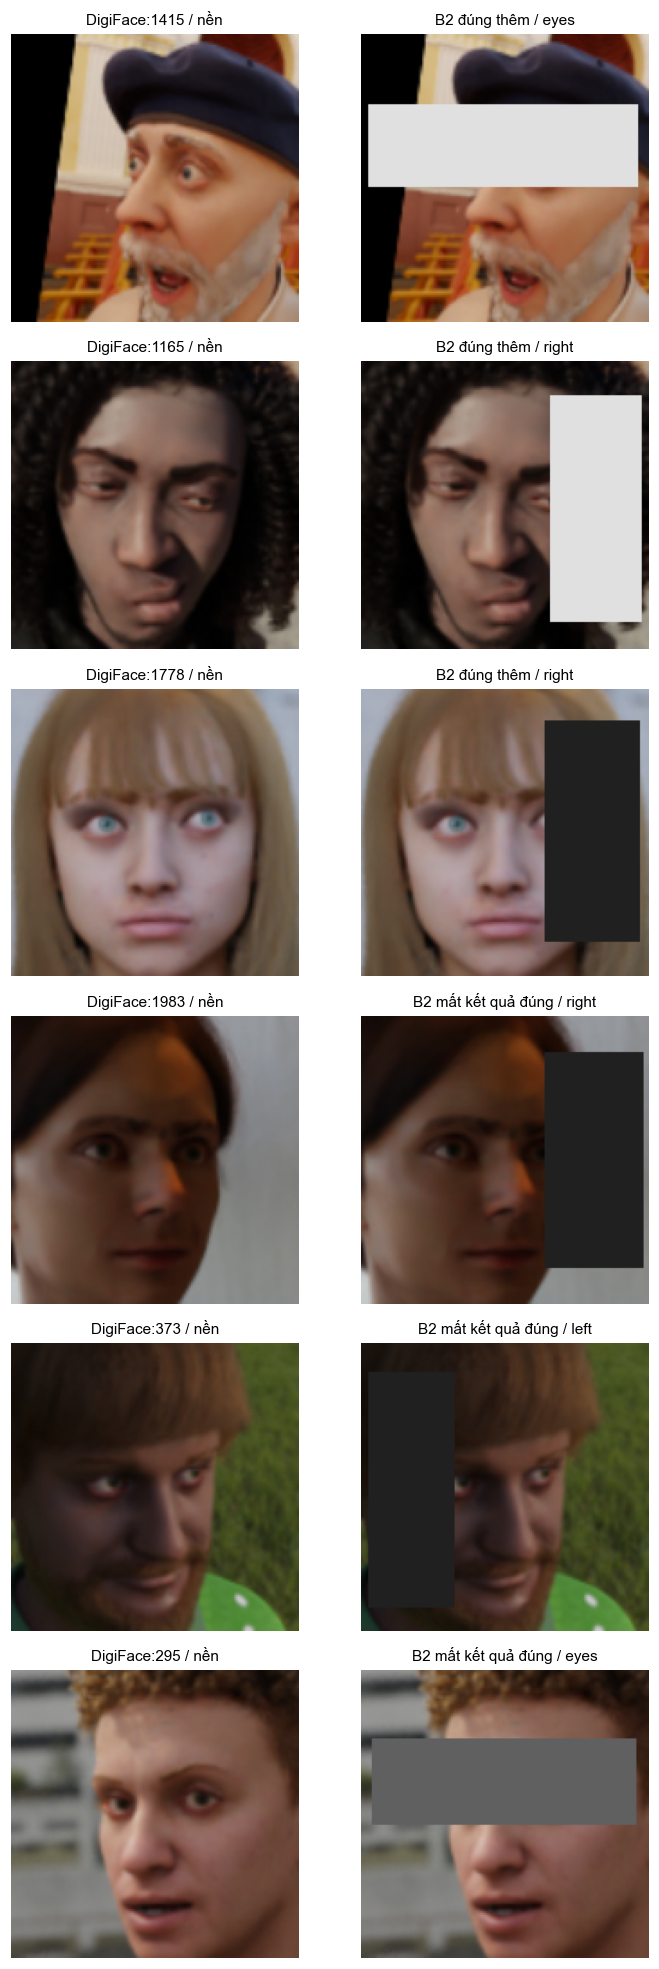

,known_occluded_queries,B2_gained,B2_lost
0,3700,106,70


In [4]:
a=occluded[occluded.run.eq('B1')&occluded.is_known].set_index('image_id')
b=occluded[occluded.run.eq('B2')&occluded.is_known].set_index('image_id')
gained=sorted(set(b[b.correct_accepted].index)-set(a[a.correct_accepted].index))
lost=sorted(set(a[a.correct_accepted].index)-set(b[b.correct_accepted].index))
selected=[(x,'B2 đúng thêm') for x in gained[:3]]+[(x,'B2 mất kết quả đúng') for x in lost[:3]]
V=pd.read_csv(ROOT/'ban_giao_nhom/augmentation/notebook_outputs/tables/01_validation_roles.csv',dtype=str,keep_default_na=False).set_index('image_id')
spec_l=spec.set_index('image_id');fig,axes=plt.subplots(len(selected),2,figsize=(7,3*len(selected)))
selection=[]
for row,(image_id,category) in enumerate(selected):
    r=V.loc[image_id]
    pixels=read_rgb160(r)
    s=spec_l.loc[image_id];masked=pixels.copy();masked[int(s.y1):int(s.y2),int(s.x1):int(s.x2)]=int(s.fill_gray)
    axes[row,0].imshow(pixels);axes[row,0].set_title(r.canonical_identity+' / nền',fontsize=10)
    axes[row,1].imshow(masked);axes[row,1].set_title(category+' / '+s.kind,fontsize=10)
    for ax in axes[row]:ax.axis('off')
    selection.append({'image_id':image_id,'category':category,'kind':s.kind,
                      'B1_hit':bool(a.loc[image_id,'correct_accepted']),'B2_hit':bool(b.loc[image_id,'correct_accepted'])})
fig.tight_layout();finish(fig,'03_benefit_and_harm_examples');save(pd.DataFrame(selection),'03_error_examples')
display(pd.DataFrame([{'known_occluded_queries':len(a),'B2_gained':len(gained),'B2_lost':len(lost)}]))

## 4. Resume thực: hai bước liên tục so với lưu/nạp giữa hai bước

Dùng checkpoint tốt nhất, clone model/optimizer rồi chạy một bước chẩn đoán. Batch gồm 32 ảnh train đầu tiên theo manifest, được đọc lại từ raw, kiểm SHA-256 rồi resize như pilot. Lưu model/optimizer/RNG vào buffer và chạy bước kế tiếp. Instance mới nạp buffer và khôi phục RNG phải ra **cùng loss và weights** sau đúng bước kế tiếp.

Hai ca âm cố tình bỏ optimizer state hoặc đổi RNG dropout phải làm kết quả khác. Các model chẩn đoán bị bỏ; không ghi đè checkpoint pilot và không tính các update này vào 432 steps/nhánh.

In [5]:
contract=json.loads((ROOT/'ban_giao_nhom/augmentation/notebook_outputs/augmentation_pilot_contract.json').read_text(encoding='utf-8'))
cfg=contract['pilot'];labels=json.loads((ROOT/'ban_giao_nhom/augmentation/notebook_outputs/label_mapping.json').read_text(encoding='utf-8'))
T=pd.read_csv(ROOT/'ban_giao_nhom/augmentation/notebook_outputs/tables/01_pilot_train.csv',dtype=str,keep_default_na=False)
TS=pd.read_csv(ROOT/'ban_giao_nhom/augmentation/notebook_outputs/tables/02_B2_train_variant_specs.csv',dtype={'seed':str})
pixels=np.stack([read_rgb160(row) for row in T.head(32).itertuples()])
catalog=pd.read_csv(PILOT/'tables/07_checkpoint_catalog.csv')
OPEN=tuple(x+'.' for x in cfg['encoder_open_layers'])
def model_from(state):
    m=InceptionResnetV1(pretrained=None,classify=True,num_classes=len(labels)).to(DEVICE);m.load_state_dict(state);m.eval();m.dropout.train();m.block8.train()
    for n,p in m.named_parameters():p.requires_grad_(n.startswith('logits.') or n.startswith(OPEN))
    for module in m.modules():
        if isinstance(module,nn.modules.batchnorm._BatchNorm):module.eval()
    return m
def optimizer_for(model):
    return torch.optim.AdamW([{'params':[p for n,p in model.named_parameters() if n.startswith('logits.')],'lr':cfg['lr_head'],'group_name':'classifier'},
                            {'params':[p for n,p in model.named_parameters() if n.startswith(OPEN)],'lr':cfg['lr_encoder'],'group_name':'encoder'}],weight_decay=cfg['weight_decay'])
def one_step(model,opt,x,y):
    opt.zero_grad(set_to_none=True);loss=F.cross_entropy(model(x),y);loss.backward()
    nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad],cfg['gradient_clip_norm']);opt.step()
    return float(loss.detach())
def max_diff(m,state):return max(float((p-state[n]).abs().max()) for n,p in m.state_dict().items() if p.dtype.is_floating_point)
diagnostics=[]
for branch in ['B1','B2']:
    epoch=summary['best_epochs'][branch];path=HERE/'checkpoints'/f'{branch}_epoch{epoch}_resume.pt'
    p=torch.load(path,map_location='cpu',weights_only=True)
    expected=catalog[catalog.branch.eq(branch)&catalog.epoch.eq(epoch)].iloc[0]
    assert sha(path)==expected.sha256
    assert state_sha({n:t for n,t in p['model_state'].items() if not n.startswith('logits.')})==expected.feature_sha256
    batch=np.array(pixels[:32],copy=True)
    if branch=='B2':
        specs=TS[TS.epoch.eq(epoch)].set_index('image_id')
        for j,image_id in enumerate(T.image_id.iloc[:32]):
            s=specs.loc[image_id]
            if s.applied:batch[j,int(s.y1):int(s.y2),int(s.x1):int(s.x2)]=int(s.fill_gray)
    x=(torch.from_numpy(batch).permute(0,3,1,2).float().to(DEVICE)-127.5)/128
    y=torch.tensor([labels[z] for z in T.canonical_identity.iloc[:32]],device=DEVICE)
    live=model_from(p['model_state']);opt=optimizer_for(live);opt.load_state_dict(p['optimizer_state'])
    torch.manual_seed(cfg['seed']+500)
    one_step(live,opt,x,y)
    buffer=io.BytesIO();torch.save({'model':{n:t.detach().cpu().clone() for n,t in live.state_dict().items()},
                                  'optimizer':copy.deepcopy(opt.state_dict()),'cpu_rng':torch.get_rng_state(),
                                  'cuda_rng':torch.cuda.get_rng_state_all()},buffer)
    reference_loss=one_step(live,opt,x,y)
    reference={n:t.detach().clone() for n,t in live.state_dict().items()}
    buffer.seek(0);point=torch.load(buffer,map_location='cpu',weights_only=True)
    restored=model_from(point['model']);ropt=optimizer_for(restored);ropt.load_state_dict(point['optimizer'])
    torch.set_rng_state(point['cpu_rng']);torch.cuda.set_rng_state_all(point['cuda_rng'])
    restored_loss=one_step(restored,ropt,x,y);diff=max_diff(restored,reference)
    assert reference_loss==restored_loss and diff==0,'Lưu/nạp giữa hai bước làm đổi training'
    wrong_opt=model_from(point['model']);wopt=optimizer_for(wrong_opt)
    torch.set_rng_state(point['cpu_rng']);torch.cuda.set_rng_state_all(point['cuda_rng']);one_step(wrong_opt,wopt,x,y)
    missing_optimizer_diff=max_diff(wrong_opt,reference);assert missing_optimizer_diff>0,'Ca âm optimizer không hiệu lực'
    wrong_rng=model_from(point['model']);gopt=optimizer_for(wrong_rng);gopt.load_state_dict(copy.deepcopy(point['optimizer']))
    torch.manual_seed(cfg['seed']+9876);one_step(wrong_rng,gopt,x,y)
    missing_rng_diff=max_diff(wrong_rng,reference);assert missing_rng_diff>0,'Ca âm RNG không hiệu lực'
    diagnostics.append({'branch':branch,'continuous_vs_resumed_loss_diff':abs(reference_loss-restored_loss),
                        'continuous_vs_resumed_max_weight_diff':diff,'missing_optimizer_max_diff':missing_optimizer_diff,
                        'missing_RNG_max_diff':missing_rng_diff,'original_checkpoint_feature_hash_matches':True})
    assert sha(path)==expected.sha256,'Diagnostic đã sửa checkpoint thật'
    del live,opt,restored,ropt,wrong_opt,wopt,wrong_rng,gopt,p,point,buffer,reference,x,y
    gc.collect();torch.cuda.empty_cache()
save(pd.DataFrame(diagnostics),'04_true_resume_and_negative_checks');display(pd.DataFrame(diagnostics))

,branch,continuous_vs_resumed_loss_diff,continuous_vs_resumed_max_weight_diff,missing_optimizer_max_diff,missing_RNG_max_diff,original_checkpoint_feature_hash_matches
0,B1,0.0,0.0,0.001841,0.000469,True
1,B2,0.0,0.0,0.001829,0.000385,True


## 5. Kết luận kiểm chứng và bước tiếp theo

Pilot đã đo được khả năng fit train/monitor, embedding trên người mới, độ bền khi che nhân tạo, chi phí và khả năng khôi phục training. B1/B2 cuối vẫn cần full cohort 1.600 người, ngân sách như nhau và nhiều seed nếu muốn kết luận ổn định.

Ước tính thời gian full epoch chỉ áp dụng chính sách mở block cuối/projection đang đo, với cache uint8. Nếu mở nhiều lớp hơn hoặc đổi input thì phải đo lại. Giữ test và ảnh thật cho bước 7 sau khi khóa cấu hình.

In [6]:
assert sha(PILOT/'execution_summary.json')==inputs['pilot_summary']
assert sha(PILOT/'tables/09_predictions.csv')==inputs['predictions']
source=json.loads((HERE/'Phan_tich_va_kiem_chung_pilot.ipynb').read_text(encoding='utf-8'))
source_sha=hashlib.sha256(json.dumps([(c['cell_type'],''.join(c['source'])) for c in source['cells']],ensure_ascii=False).encode()).hexdigest()
report={'checks':'PASS','metrics_recomputed':len(recomputed),'per_kind_groups':len(per_kind),
        'true_resume_branches':len(diagnostics),'negative_resume_faults_detected':2*len(diagnostics),
        'diagnostic_raw_train_images_hashed':len(pixels),'pilot_pixel_cache_required':False,
        'pilot_checkpoints_modified':False,'training_budget_changed':False,'test_used':False,'external_used':False,
        'source_sha256':source_sha,'input_sha256':inputs,'elapsed_seconds':time.perf_counter()-START,
        'executed_at_utc':datetime.now(timezone.utc).isoformat()}
(OUT/'execution_summary.json').write_text(json.dumps(report,ensure_ascii=False,indent=2),encoding='utf-8')
display(Markdown('**Đạt:** tái tính metrics từ CSV, phân tích bốn kiểu che, checkpoint khớp hash trọng số trước lưu, '
                 'resume tương đương chuỗi không ngắt và các ca âm optimizer/RNG đều được phát hiện. '
                 'Không cộng diagnostic vào số bước train hoặc sửa kết quả pilot đã lưu.'))

**Đạt:** tái tính metrics từ CSV, phân tích bốn kiểu che, checkpoint khớp hash trọng số trước lưu, resume tương đương chuỗi không ngắt và các ca âm optimizer/RNG đều được phát hiện. Không cộng diagnostic vào số bước train hoặc sửa kết quả pilot đã lưu.